# Hanehalkı Elektrik Tüketiminin Derin Öğrenme ile Saatlik Tahmini
**Makine ve Derin Öğrenme Uygulamaları — Proje Envanteri** · Muhammed Mirhan Serim · Software Persona YZ Programı, 30. Dönem

**Tür:** DL – Zaman serisi (LSTM / GRU), klasik ML temel modeliyle karşılaştırmalı
**Amaç:** Bir hanenin son 24 saatlik tüketiminden bir sonraki saatin elektrik tüketimini tahmin etmek.

## 1. Problem Tanımı
**Girdi:** Hanenin son 24 saatteki ortalama aktif güç tüketimi (kW) ve saat/gün bilgisi.
**Çıktı:** Bir sonraki saatteki ortalama aktif güç tüketimi (kW). Problem bir **regresyon / zaman serisi tahmini** problemidir.
**Gerçek dünya ihtiyacı:** Kısa vadeli yük tahmini; dağıtım şirketlerinin üretim-tüketim dengesini kurması, akıllı ev sistemlerinin
pahalı saatlerde yükü kaydırması ve kullanıcıya anormal tüketim uyarısı verilmesi için temel bileşendir.

In [1]:
import os, io, zipfile, urllib.request, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
SEED = 42; np.random.seed(SEED); torch.manual_seed(SEED)
CIHAZ = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("Cihaz:", CIHAZ, "| PyTorch", torch.__version__)

Cihaz: mps | PyTorch 2.14.1


## 2. Veri Setinin Tanıtılması
**Kaynak:** UCI Machine Learning Repository — *Individual Household Electric Power Consumption* (Hebrail & Berard, 2012, CC BY 4.0).
Fransa'da Sceaux'daki tek bir hanenin Aralık 2006 – Kasım 2010 arasındaki **dakikalık** ölçümleri (≈ 2,07 milyon satır, 9 sütun).

| Değişken | Anlamı |
|---|---|
| `Global_active_power` | Hanenin toplam aktif gücü (kW) — **hedef** |
| `Global_reactive_power`, `Voltage`, `Global_intensity` | Reaktif güç (kW), gerilim (V), akım (A) |
| `Sub_metering_1/2/3` | Mutfak, çamaşır odası, su ısıtıcı + klima alt sayaçları (Wh) |

Eksik ölçümler `?` ile işaretlenmiştir. Dakikalık veri, problem amacına uygun olarak **saatlik ortalamaya** indirgenir.

In [2]:
DOSYA = "household_power_consumption.txt"
if not os.path.exists(DOSYA):
    url = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"
    zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())).extractall(".")
ham = pd.read_csv(DOSYA, sep=";", na_values="?", low_memory=False)
ham["Zaman"] = pd.to_datetime(ham["Date"] + " " + ham["Time"], format="%d/%m/%Y %H:%M:%S")
ham = ham.drop(columns=["Date", "Time"]).set_index("Zaman")
print("Dakikalık veri:", ham.shape, "|", ham.index.min(), "→", ham.index.max())
print("Eksik oranı (%):", round(ham["Global_active_power"].isna().mean() * 100, 2))

Dakikalık veri: (2075259, 7) | 2006-12-16 17:24:00 → 2010-11-26 21:02:00
Eksik oranı (%): 1.25


## 3. Veri Keşfi

In [3]:
saatlik = ham.resample("h").mean()
print("Saatlik veri:", saatlik.shape, "| saatlik eksik:", int(saatlik["Global_active_power"].isna().sum()))
saatlik["Global_active_power"].describe().round(3)

Saatlik veri: (34589, 7) | saatlik eksik: 421


count    34168.000
mean         1.092
std          0.898
min          0.124
25%          0.342
50%          0.803
75%          1.579
max          6.561
Name: Global_active_power, dtype: float64

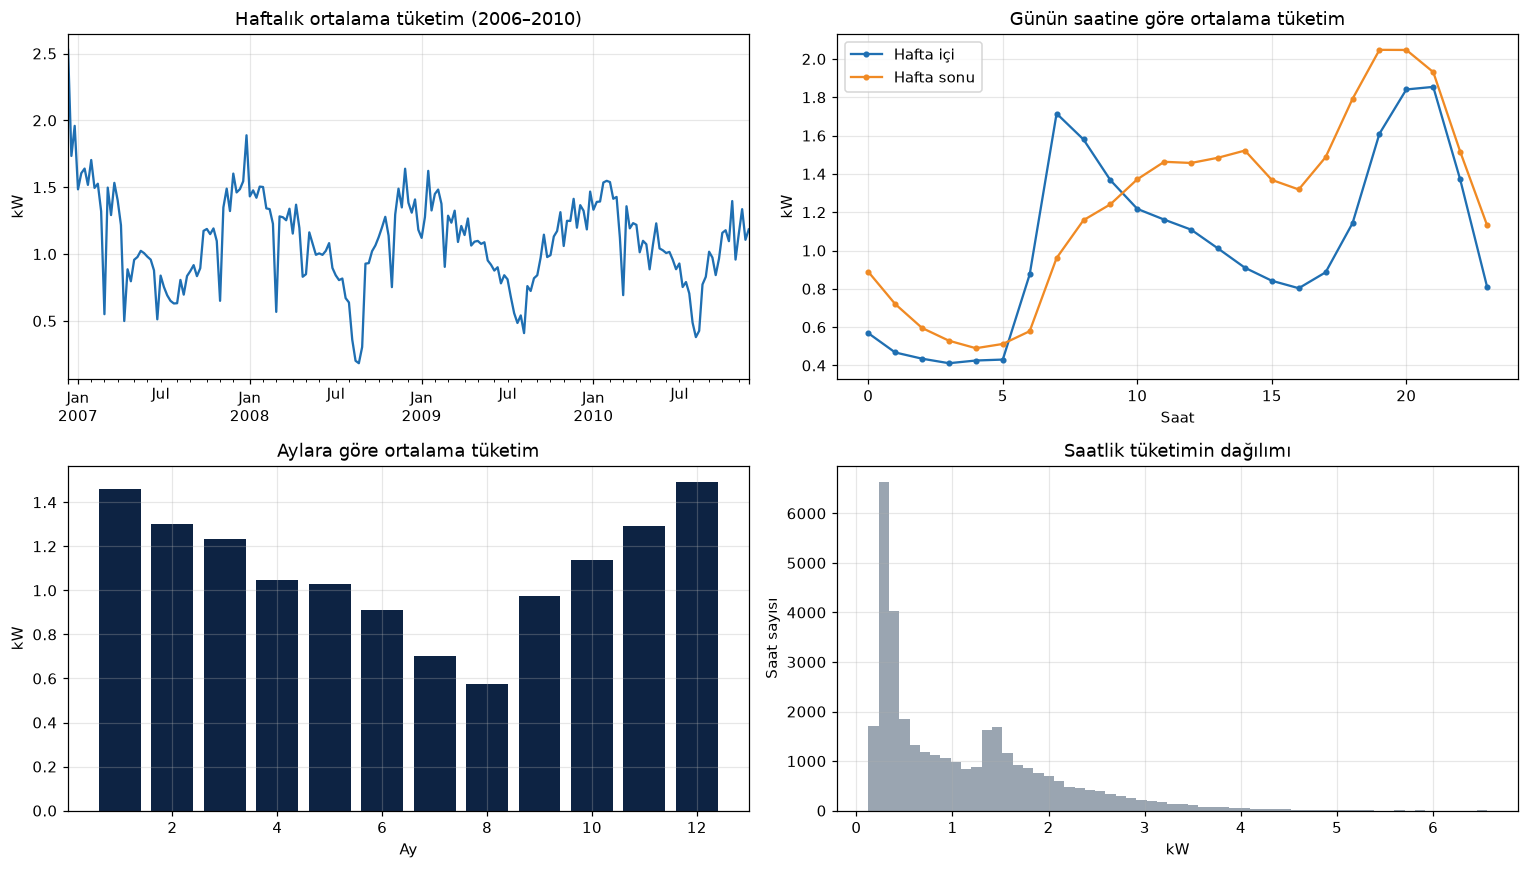

In [4]:
g = saatlik["Global_active_power"]
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
g.resample("W").mean().plot(ax=ax[0, 0], color="#1f6fb2")
ax[0, 0].set_title("Haftalık ortalama tüketim (2006–2010)"); ax[0, 0].set_ylabel("kW"); ax[0, 0].set_xlabel("")

gun_saat = g.groupby([g.index.dayofweek >= 5, g.index.hour]).mean().unstack(0)
ax[0, 1].plot(gun_saat.index, gun_saat[False], marker="o", ms=3, label="Hafta içi", color="#1f6fb2")
ax[0, 1].plot(gun_saat.index, gun_saat[True], marker="o", ms=3, label="Hafta sonu", color="#f08a24")
ax[0, 1].set_title("Günün saatine göre ortalama tüketim"); ax[0, 1].set_xlabel("Saat"); ax[0, 1].set_ylabel("kW"); ax[0, 1].legend()

ay = g.groupby(g.index.month).mean()
ax[1, 0].bar(ay.index, ay.values, color="#0d2343")
ax[1, 0].set_title("Aylara göre ortalama tüketim"); ax[1, 0].set_xlabel("Ay"); ax[1, 0].set_ylabel("kW")

ax[1, 1].hist(g.dropna(), bins=60, color="#9aa5b1")
ax[1, 1].set_title("Saatlik tüketimin dağılımı"); ax[1, 1].set_xlabel("kW"); ax[1, 1].set_ylabel("Saat sayısı")
plt.tight_layout(); plt.savefig("g1_kesif.png", dpi=150, bbox_inches="tight"); plt.show()

In [5]:
ozet = pd.DataFrame({"gecikme (saat)": [1, 2, 24, 168]})
ozet["otokorelasyon"] = [round(g.autocorr(l), 3) for l in ozet["gecikme (saat)"]]
alt = saatlik[["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]].mean() * 60 / 1000  # Wh/dk → kW
print(ozet.to_string(index=False))
print("\nAlt sayaçların ortalama payı (kW):", alt.round(3).to_dict(), "| toplam ortalama:", round(g.mean(), 3))

 gecikme (saat)  otokorelasyon
              1          0.713
              2          0.465
             24          0.436
            168          0.461

Alt sayaçların ortalama payı (kW): {'Sub_metering_1': 0.067, 'Sub_metering_2': 0.078, 'Sub_metering_3': 0.388} | toplam ortalama: 1.092


**Gözlemler**
1. **Belirgin yıllık mevsimsellik:** Kış aylarında tüketim yazın yaklaşık iki katı. Ağustos en düşük ay (tatil dönemi).
2. **Günlük örüntü:** Sabah 07–09 ve akşam 19–22 arasında iki tepe var. Hafta sonu sabah tepesi daha geç ve gün içi tüketim daha yüksek.
3. **Güçlü kısa vadeli bağımlılık:** 1 saatlik otokorelasyon yüksek, 24 ve 168 saatlik gecikmeler de anlamlı. Bu, geçmiş saatlerden
   tahmin yapmanın mantıklı olduğunu gösteriyor.
4. **Sağa çarpık dağılım:** Çoğu saat 0,3–1,5 kW arasında, ama ani yüksek tüketim saatleri (ısıtıcı, fırın vb.) tahmini zorlaştırıyor.

## 4. Veri Ön İşleme
- **Eksik değer:** Dakikalık verideki boşluklar (%1,25) saatlik ortalamada büyük ölçüde kayboluyor. Kalan boş saatler (uzun kesintiler)
  zaman bazlı doğrusal interpolasyonla dolduruldu.
- **Özellikler:** Hedef serinin kendisi + günün saati ve haftanın günü (sinüs/kosinüs kodlaması, döngüsel yapıyı korumak için).
- **Pencereleme:** Son **24 saat** → sonraki **1 saat**.
- **Kronolojik bölme (sızıntıyı önlemek için karıştırmadan):** Eğitim: 2006-12 → 2009-12 · Doğrulama: 2010-01 → 2010-05 · Test: 2010-06 → 2010-11
- **Ölçekleme:** Min-max normalizasyonu **yalnızca eğitim verisinden** öğrenildi ve diğer bölümlere uygulandı.

In [6]:
seri = saatlik["Global_active_power"].interpolate(method="time")
df = pd.DataFrame({"y": seri})
df["saat_sin"] = np.sin(2 * np.pi * df.index.hour / 24); df["saat_cos"] = np.cos(2 * np.pi * df.index.hour / 24)
df["gun_sin"] = np.sin(2 * np.pi * df.index.dayofweek / 7); df["gun_cos"] = np.cos(2 * np.pi * df.index.dayofweek / 7)
df = df.dropna()

egitim_son, dogrulama_son = "2009-12-31 23:00", "2010-05-31 23:00"
y_min, y_max = df.loc[:egitim_son, "y"].min(), df.loc[:egitim_son, "y"].max()
df["y_olcekli"] = (df["y"] - y_min) / (y_max - y_min)

PENCERE = 24
OZ = ["y_olcekli", "saat_sin", "saat_cos", "gun_sin", "gun_cos"]
deger = df[OZ].values.astype(np.float32); hedef = df["y_olcekli"].values.astype(np.float32)
X_tum = np.stack([deger[i - PENCERE:i] for i in range(PENCERE, len(df))])
y_tum = hedef[PENCERE:]; zaman = df.index[PENCERE:]

m_eg = zaman <= egitim_son; m_dg = (zaman > egitim_son) & (zaman <= dogrulama_son); m_ts = zaman > dogrulama_son
X_eg, y_eg, X_dg, y_dg, X_ts, y_ts = X_tum[m_eg], y_tum[m_eg], X_tum[m_dg], y_tum[m_dg], X_tum[m_ts], y_tum[m_ts]
print("Pencere şekli (örnek, zaman adımı, özellik):", X_tum.shape)
print(f"Eğitim: {len(y_eg)} · Doğrulama: {len(y_dg)} · Test: {len(y_ts)} saat")
geri = lambda v: v * (y_max - y_min) + y_min   # ölçeği kW'a geri çevirir

Pencere şekli (örnek, zaman adımı, özellik): (34565, 24, 5)
Eğitim: 26647 · Doğrulama: 3624 · Test: 4294 saat


## 5. Model Seçimi / Tasarımı
Karşılaştırma merdiveni, karmaşık modelin gerçekten katkı sağlayıp sağlamadığını görmek için kuruldu:

| Model | Tür | Açıklama |
|---|---|---|
| Naif (bir önceki saat) | Temel çizgi | Sonraki saat = son saat |
| Mevsimsel naif (24 saat önce) | Temel çizgi | Sonraki saat = dünkü aynı saat |
| Doğrusal Regresyon | Klasik ML | 24 gecikme + zaman özellikleri (düzleştirilmiş pencere) |
| **LSTM** | Derin öğrenme | 2 katman × 64 gizli birim, dropout 0,2, son adım → Dense(1) |
| **GRU** | Derin öğrenme | LSTM ile aynı yapı; daha az parametreli kapı mekanizması |

**Neden LSTM/GRU?** Tüketim, saatler arası bağımlılığı olan sıralı bir veri. Tekrarlayan ağlar geçmişi gizli durumda taşıyarak hem kısa
vadeli (son saatler) hem günlük örüntüleri öğrenebiliyor. Çıkış katmanı tek nöronlu ve aktivasyonsuz (regresyon).
**Kayıp fonksiyonu:** MSE · **Optimizer:** Adam (lr = 0,001).

In [7]:
class TekrarlayanModel(nn.Module):
    def __init__(self, hucre="LSTM", girdi=len(OZ), gizli=64, katman=2, dropout=0.2):
        super().__init__()
        rnn = nn.LSTM if hucre == "LSTM" else nn.GRU
        self.rnn = rnn(girdi, gizli, num_layers=katman, batch_first=True, dropout=dropout)
        self.cikis = nn.Linear(gizli, 1)
    def forward(self, x):
        h, _ = self.rnn(x)
        return self.cikis(h[:, -1, :]).squeeze(-1)

for h in ["LSTM", "GRU"]:
    print(h, "parametre sayısı:", sum(p.numel() for p in TekrarlayanModel(h).parameters()))

LSTM parametre sayısı: 51521
GRU parametre sayısı: 38657


## 6. Model Eğitimi
- **Epoch:** en fazla 30 · **Batch size:** 256 · **Doğrulama:** ayrı bir zaman dilimi (2010 Ocak–Mayıs)
- **Erken durdurma:** Doğrulama kaybı 5 epoch boyunca iyileşmezse eğitim durur ve en iyi ağırlıklar geri yüklenir.
- Doğrusal regresyon aynı eğitim pencereleriyle kapalı formda eğitildi.

In [8]:
def egit(hucre, epoch=30, batch=256, sabir=5):
    torch.manual_seed(SEED)
    model = TekrarlayanModel(hucre).to(CIHAZ)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3); kayip_fn = nn.MSELoss()
    Xe, ye = torch.tensor(X_eg), torch.tensor(y_eg)
    Xd, yd = torch.tensor(X_dg).to(CIHAZ), torch.tensor(y_dg).to(CIHAZ)
    gecmis = {"egitim": [], "dogrulama": []}; en_iyi, en_iyi_durum, bekle = 1e9, None, 0
    for ep in range(epoch):
        model.train(); sira = torch.randperm(len(Xe)); toplam = 0.0
        for i in range(0, len(Xe), batch):
            idx = sira[i:i + batch]; xb, yb = Xe[idx].to(CIHAZ), ye[idx].to(CIHAZ)
            opt.zero_grad(); kayip = kayip_fn(model(xb), yb); kayip.backward(); opt.step()
            toplam += kayip.item() * len(idx)
        model.eval()
        with torch.no_grad(): dk = kayip_fn(model(Xd), yd).item()
        gecmis["egitim"].append(toplam / len(Xe)); gecmis["dogrulama"].append(dk)
        if dk < en_iyi - 1e-6: en_iyi, en_iyi_durum, bekle = dk, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else: bekle += 1
        if bekle >= sabir: break
    model.load_state_dict(en_iyi_durum)
    print(f"{hucre}: {len(gecmis['egitim'])} epoch, en iyi doğrulama MSE = {en_iyi:.5f}")
    return model, gecmis

def tahmin(model, X):
    model.eval()
    with torch.no_grad(): return model(torch.tensor(X).to(CIHAZ)).cpu().numpy()

t0 = time.time(); lstm, gecmis_lstm = egit("LSTM"); print(f"süre: {time.time() - t0:.0f} s")
t0 = time.time(); gru, gecmis_gru = egit("GRU");  print(f"süre: {time.time() - t0:.0f} s")
lr = LinearRegression().fit(X_eg.reshape(len(X_eg), -1), y_eg)

LSTM: 25 epoch, en iyi doğrulama MSE = 0.00687
süre: 13 s


GRU: 27 epoch, en iyi doğrulama MSE = 0.00678
süre: 42 s


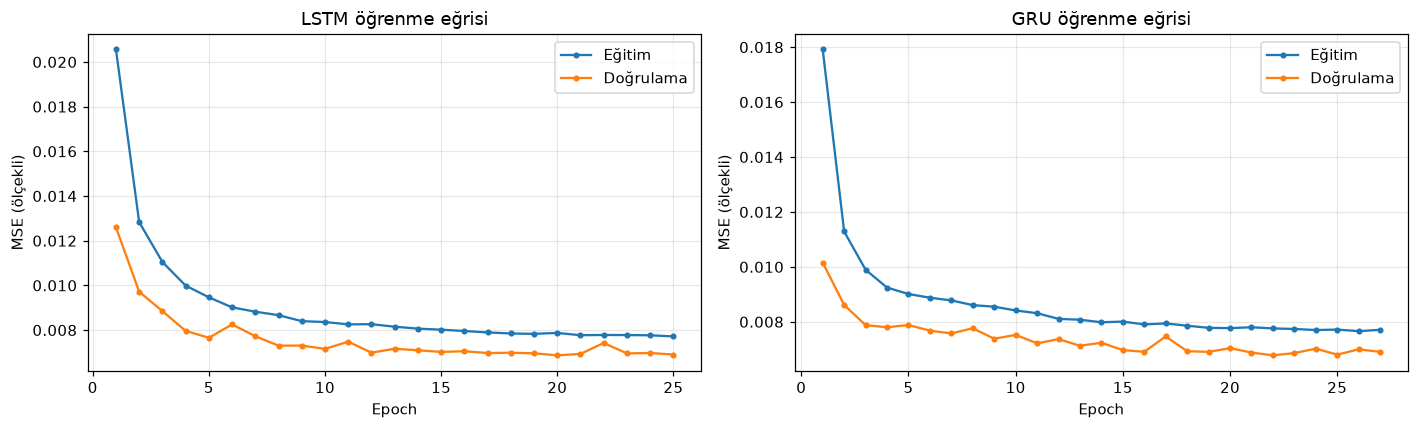

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, (ad, g_) in zip(ax, [("LSTM", gecmis_lstm), ("GRU", gecmis_gru)]):
    a.plot(range(1, len(g_["egitim"]) + 1), g_["egitim"], marker="o", ms=3, label="Eğitim")
    a.plot(range(1, len(g_["dogrulama"]) + 1), g_["dogrulama"], marker="o", ms=3, label="Doğrulama")
    a.set_title(f"{ad} öğrenme eğrisi"); a.set_xlabel("Epoch"); a.set_ylabel("MSE (ölçekli)"); a.legend()
plt.tight_layout(); plt.savefig("g2_ogrenme.png", dpi=150, bbox_inches="tight"); plt.show()

## 7. Model Değerlendirme

In [10]:
gercek = geri(y_ts)
olcek_naif = X_ts[:, -1, 0]                                  # son saat
idx_ts = np.where(m_ts)[0] + PENCERE                          # df içindeki konum
mevsimsel = df["y_olcekli"].values[idx_ts - 24]               # 24 saat önce
tahminler = {
    "Naif (önceki saat)": geri(olcek_naif),
    "Mevsimsel naif (24 sa önce)": geri(mevsimsel),
    "Doğrusal Regresyon": geri(lr.predict(X_ts.reshape(len(X_ts), -1))),
    "LSTM": geri(tahmin(lstm, X_ts)),
    "GRU": geri(tahmin(gru, X_ts)),
}
sonuc = pd.DataFrame([{"Model": ad, "MAE (kW)": mean_absolute_error(gercek, p),
                       "RMSE (kW)": mean_squared_error(gercek, p) ** 0.5, "R²": r2_score(gercek, p)}
                      for ad, p in tahminler.items()]).round(3)
sonuc

,Model,MAE (kW),RMSE (kW),R²
0,Naif (önceki saat),0.366,0.566,0.342
1,Mevsimsel naif (24 sa önce),0.482,0.726,-0.085
2,Doğrusal Regresyon,0.348,0.488,0.511
3,LSTM,0.344,0.478,0.530
4,GRU,0.324,0.467,0.550


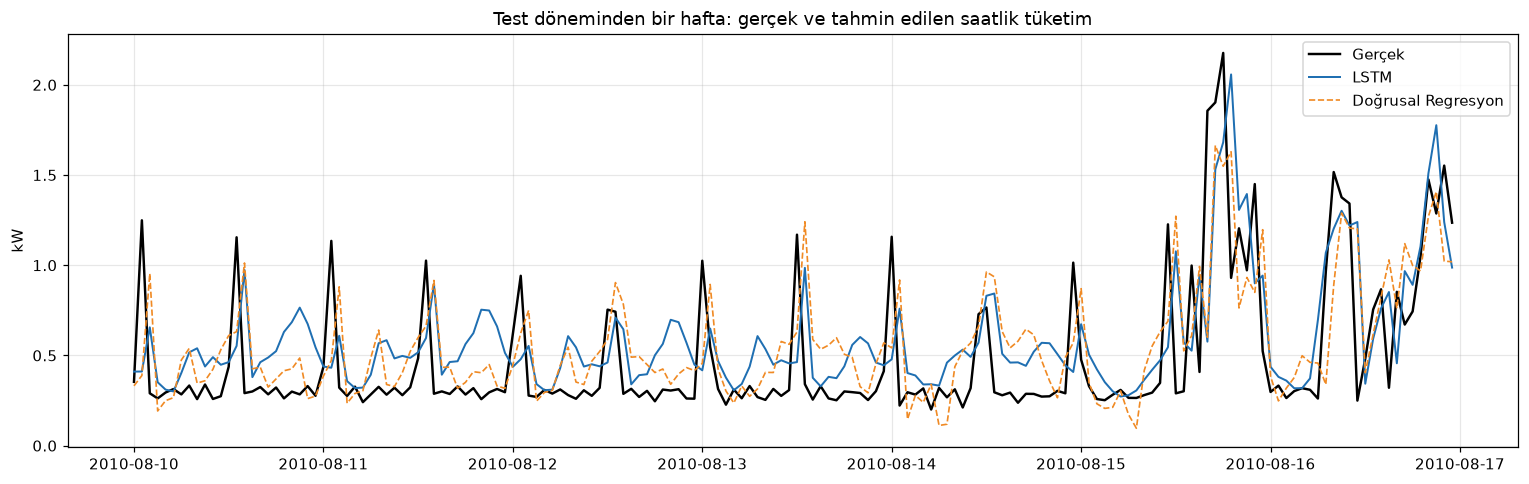

In [11]:
fig, ax = plt.subplots(figsize=(14, 4.5))
aralik = slice(24 * 7 * 10, 24 * 7 * 11)   # testten bir hafta (Ağustos ortası)
z = zaman[m_ts][aralik]
ax.plot(z, gercek[aralik], color="black", lw=1.6, label="Gerçek")
ax.plot(z, tahminler["LSTM"][aralik], color="#1f6fb2", lw=1.3, label="LSTM")
ax.plot(z, tahminler["Doğrusal Regresyon"][aralik], color="#f08a24", lw=1.1, ls="--", label="Doğrusal Regresyon")
ax.set_title("Test döneminden bir hafta: gerçek ve tahmin edilen saatlik tüketim"); ax.set_ylabel("kW"); ax.legend()
plt.tight_layout(); plt.savefig("g3_tahmin_hafta.png", dpi=150, bbox_inches="tight"); plt.show()

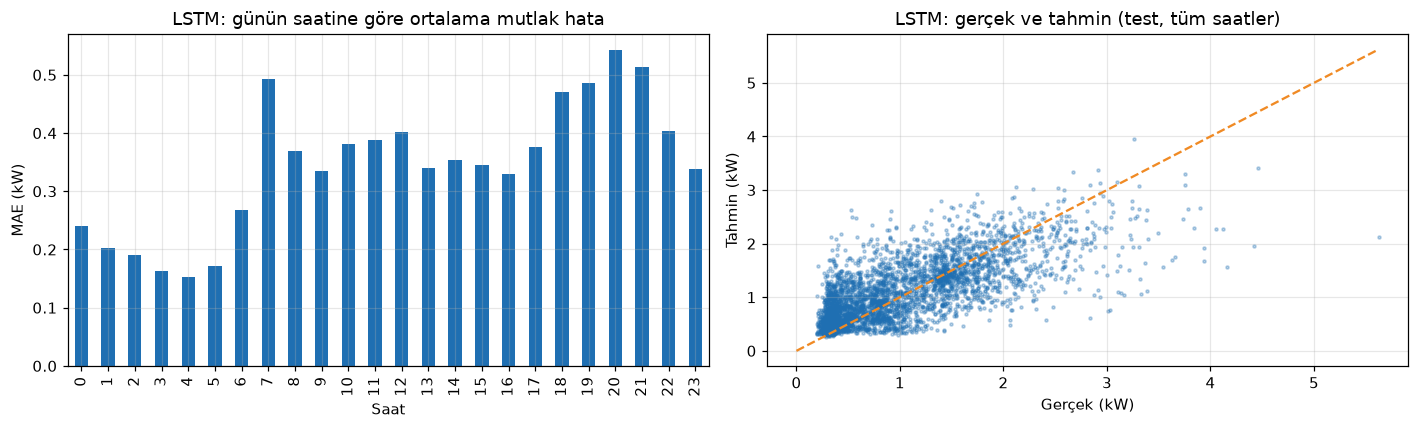

En yüksek %10'luk saatlerde LSTM MAE: 0.662 kW | diğer saatlerde: 0.309 kW
Ortalama tahmin / ortalama gerçek (yüksek saatler): 1.873 / 2.438


In [12]:
hata = np.abs(gercek - tahminler["LSTM"])
saat = zaman[m_ts].hour
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
pd.Series(hata).groupby(saat).mean().plot(kind="bar", ax=ax[0], color="#1f6fb2")
ax[0].set_title("LSTM: günün saatine göre ortalama mutlak hata"); ax[0].set_xlabel("Saat"); ax[0].set_ylabel("MAE (kW)")
ax[1].scatter(gercek, tahminler["LSTM"], s=4, alpha=0.3, color="#1f6fb2")
ax[1].plot([0, gercek.max()], [0, gercek.max()], "--", color="#f08a24")
ax[1].set_title("LSTM: gerçek ve tahmin (test, tüm saatler)"); ax[1].set_xlabel("Gerçek (kW)"); ax[1].set_ylabel("Tahmin (kW)")
plt.tight_layout(); plt.savefig("g4_hata.png", dpi=150, bbox_inches="tight"); plt.show()

yuksek = gercek > np.percentile(gercek, 90)
print("En yüksek %10'luk saatlerde LSTM MAE:", round(hata[yuksek].mean(), 3), "kW | diğer saatlerde:", round(hata[~yuksek].mean(), 3), "kW")
print("Ortalama tahmin / ortalama gerçek (yüksek saatler):", round(tahminler['LSTM'][yuksek].mean(), 3), "/", round(gercek[yuksek].mean(), 3))

## 8. Sonuçların Yorumlanması
Sonuçlar yukarıdaki tabloda ve grafiklerde yer alıyor. Ayrıntılı yorum, hata analizi ve geliştirme önerileri proje raporunda.
Raporun özet çıkarımları:
- Derin öğrenme modelleri her iki naif temel çizgiyi açık farkla geçiyor. Doğrusal regresyona karşı kazanım ise daha sınırlı:
  kısa vadeli tahminde bilginin çoğu son birkaç saatte.
- Modeller ani tüketim tepelerini geç yakalıyor ve büyüklüğünü düşük tahmin ediyor. Hata, en yüksek %10'luk saatlerde belirgin biçimde artıyor.
- Geliştirme yönleri: hava durumu (sıcaklık) gibi dış değişkenler, daha uzun pencere (168 saat), çok adımlı tahmin ve
  tepe saatlere ağırlık veren kayıp fonksiyonları.